# M14 - Video AI and traffic analytics

**Level 3 · CPU-only · about 2 hours · no download required**

A video is a sequence of images plus time. The hard parts are not the individual
detections: they are keeping identity across frames, counting an object once, and
reporting a rate that the clip actually supports. This notebook renders a synthetic
traffic scene with exact ground truth, tracks it, counts a tripwire, measures the
tracking errors, and shows where a naive pipeline breaks.

## Learning objectives

By the end of this notebook you can:

1. describe frames, fps, frame index, and real time;
2. inspect a contact sheet and per-frame ground truth;
3. run background subtraction and explain what it does and does not detect;
4. trace an IoU tracker with velocity prediction and a confirmation delay;
5. count line crossings once per track and compare with expected events;
6. compute MOTA-style tracking errors and explain identity switches;
7. report flow in vehicles per second without pretending a short clip is an hourly forecast.

## Prerequisites

- M11-M12: images, boxes, IoU, and detection metrics.
- Python 3.12 with `numpy`, `opencv-python`, `pandas`, `torch` (for the tracker only).
- CPU only. The scene is rendered in code; no video download and no GPU.

## Conceptual explanation

At 10 fps, a 60-frame clip is 6 seconds. Each frame is a still image, and the
ground-truth boxes are generated from the same trajectories that draw the vehicles.
That makes the data unusually honest: you can compare a predicted count with the
generator's expected count instead of trusting a hand count.

A tracker links detections across frames. This one matches predicted boxes by IoU,
keeps a track alive for a few missed frames, and reports it only after two hits. The
confirmation delay suppresses one-frame false positives; the coasting period survives
short occlusions. Both are product decisions with failure modes, not free accuracy.

A line counter is geometry plus memory. It records which side of the line each track
was last on and emits an event when the sign changes. The anchor matters: a box centre
and a bottom-centre contact point cross a road line at different moments, and near an
edge that difference changes the count.

## Important terminology

| Term | Meaning |
| --- | --- |
| fps | Frames per second; 10 fps means 0.1 s between frames |
| Track | One object followed across frames, with a persistent id |
| MOTA | 1 - (FN + FP + ID switches) / ground-truth objects |
| ID switch | A truth object matched to a different predicted id than before |
| Fragmentation | A track that disappears and resumes under the same id |
| Tripwire | A virtual line; a crossing emits a count event |
| Occlusion | An object hidden by another; ground truth still contains it |
| RTF | Processing seconds divided by video seconds; below 1 is faster than real time |


## 1. Set up imports and render the scene


In [1]:
from pathlib import Path
import sys

ROOT = Path.cwd().parents[1]
PROJECT = ROOT / "projects" / "video-ai"
sys.path.insert(0, str(PROJECT))
print("Repository root:", ROOT.name)
print("Section package:", PROJECT.name)


Repository root: AITopics
Section package: video-ai


In [2]:
import time

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from video_core import counting, labels, metrics, synth, tracking, video

torch_available = True
try:
    import torch
except ImportError:
    torch_available = False

print("OpenCV:", cv2.__version__)
print("torch available (tracker):", torch_available)
print("classes:", labels.LABELS)


OpenCV: 5.0.0
torch available (tracker): True
classes: ('car', 'motorcycle', 'bus', 'truck')


## 2. Render frames and inspect the contact sheet

The contact sheet is a quick data audit: are the frames different, is the camera
static, are vehicles entering and leaving? Ground truth is returned per frame,
including vehicles that are partly occluded.


rendered frames: 60 in 0.18 s
frame shape: (360, 640, 3) | fps: 10.0
objects in frame 0: 8
objects in frame 30: 8
total ground-truth boxes: 480


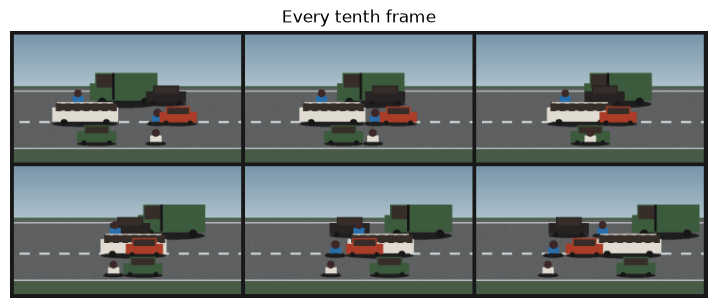

In [3]:
config = synth.make_traffic_config(
    condition="day",
    seed=4,
    frames=60,
    n_vehicles=8,
    direction="both",
    shake=0.0,
    name="day-seed4",
)
started = time.perf_counter()
frames = synth.render_scene(config)
print("rendered frames:", len(frames), "in", round(time.perf_counter() - started, 2), "s")
print("frame shape:", frames[0][0].shape, "| fps:", config.fps)
print("objects in frame 0:", len(frames[0][1]))
print("objects in frame 30:", len(frames[30][1]))
print("total ground-truth boxes:", sum(len(objects) for _, objects in frames))

sheet = video.contact_sheet([frame for frame, _ in frames[::10]], cols=3, thumb=(240, 135))
plt.figure(figsize=(9, 5))
plt.imshow(cv2.cvtColor(sheet, cv2.COLOR_BGR2RGB))
plt.axis("off")
plt.title("Every tenth frame")
plt.show()


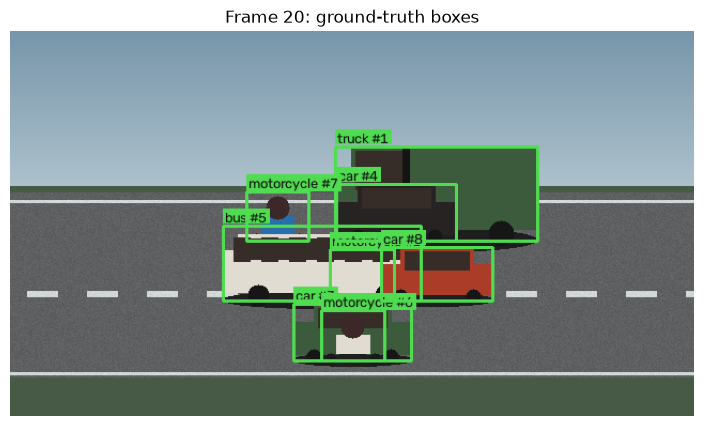

,track_id,class,box,occluded
0,1,truck,"[303.87, 108.0, 492.87, 196.0]",0.000
1,2,motorcycle,"[299.04, 204.0, 359.04, 252.0]",0.000
2,3,car,"[264.74, 255.0, 374.74, 308.0]",0.000
3,4,car,"[304.83, 143.0, 416.83, 196.0]",0.186
4,5,bus,"[198.78, 182.0, 383.78, 252.0]",0.000
5,6,motorcycle,"[290.91, 261.0, 349.91, 308.0]",0.000
6,7,motorcycle,"[221.16, 150.0, 279.16, 196.0]",0.304
7,8,car,"[347.08, 202.0, 451.08, 252.0]",0.000


In [4]:
frame_index = 20
frame, objects = frames[frame_index]
annotated = video.annotate_frame(
    frame,
    [obj["box"] for obj in objects],
    [f"{obj['class']} #{obj['track_id']}" for obj in objects],
)
plt.figure(figsize=(10, 5))
plt.imshow(cv2.cvtColor(annotated, cv2.COLOR_BGR2RGB))
plt.axis("off")
plt.title(f"Frame {frame_index}: ground-truth boxes")
plt.show()
pd.DataFrame(objects)


## 3. Background subtraction is a baseline, not a detector

A background model learns the static scene and marks pixels that differ. It finds
motion, not class or identity. Shadows, camera shake, and a stopped vehicle all
break the simple version. Use it as a sanity check and as a cheap proposal source,
not as the final system.


mask shape: (360, 640)
fraction of foreground pixels: 0.0292


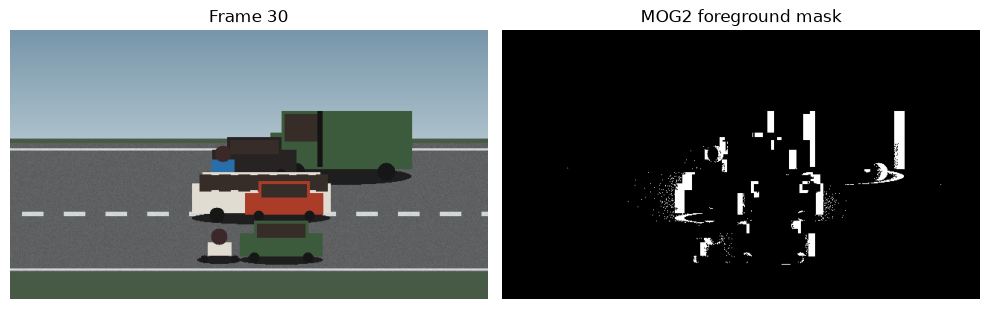

In [5]:
subtractor = cv2.createBackgroundSubtractorMOG2(history=30, varThreshold=16, detectShadows=False)
masks = []
for frame, _ in frames:
    masks.append(subtractor.apply(frame))

mask = masks[30]
print("mask shape:", mask.shape)
print("fraction of foreground pixels:", round(float((mask > 0).mean()), 4))
plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1)
plt.imshow(cv2.cvtColor(frames[30][0], cv2.COLOR_BGR2RGB))
plt.axis("off")
plt.title("Frame 30")
plt.subplot(1, 2, 2)
plt.imshow(mask, cmap="gray")
plt.axis("off")
plt.title("MOG2 foreground mask")
plt.tight_layout()
plt.show()


## 4. Define the tripwire and count oracle tracks

`counting_line` computes the expected crossings from the generator's own
trajectories. The first counter run uses the exact ground-truth boxes, so it should
reproduce the expected total. If it does not, the bug is in the geometry or anchor,
not in a model.


In [6]:
line = synth.counting_line(config, kind="vertical", at=0.55)
print("line:", line["p1"], "to", line["p2"])
print("expected crossings:", line["expected_total"])
print("per class:", pd.Series([event["class"] for event in line["expected_crossings"]]).value_counts().to_dict())

truth_tracks = [objects for _, objects in frames]
counter_tracks = [
    [{**obj, "label": labels.LABEL_TO_INDEX[obj["class"]]} for obj in objects]
    for objects in truth_tracks
]
oracle = counting.run_counter(counter_tracks, line["p1"], line["p2"], anchor="center")
oracle_report = metrics.counting_report(line["expected_crossings"], oracle["events"])
print("oracle total:", oracle["total"])
print("exact:", oracle_report["exact"], "| absolute error:", oracle_report["absolute_error"])
pd.DataFrame(oracle_report["per_class_direction"]).T


line: [352.0, 135.9] to [352.0, 342.0]
expected crossings: 8
per class: {'motorcycle': 3, 'car': 3, 'truck': 1, 'bus': 1}
oracle total: 8
exact: True | absolute error: 0


,expected,counted
bus:positive,1,1
car:negative,2,2
car:positive,1,1
motorcycle:negative,2,2
motorcycle:positive,1,1
truck:positive,1,1


## 5. Simulate detector errors and run the tracker

The tracker does not see ground truth. To make the experiment realistic, this cell
drops one detection every eleventh frame and jitters every box by a pixel or two.
The tracker must survive those misses through prediction and coasting. Then compare
its output with the truth, including ID switches and fragments.


In [7]:
rng = np.random.default_rng(7)
detections_by_frame = []
for index, (_, objects) in enumerate(frames):
    detections = []
    for obj_index, obj in enumerate(objects):
        if index % 11 == 0 and obj_index == 0:
            continue
        box = np.asarray(obj["box"], dtype=float)
        box[[0, 2]] += rng.normal(0, 1.5, 2)
        box[[1, 3]] += rng.normal(0, 1.5, 2)
        detections.append(
            metrics.Detection(
                box=box.tolist(),
                label=labels.LABEL_TO_INDEX[obj["class"]],
                score=0.9,
            )
        )
    detections_by_frame.append(detections)

track_started = time.perf_counter()
tracks = tracking.track_detections(detections_by_frame, iou_threshold=0.30, max_age=6, min_hits=2)
tracking_seconds = time.perf_counter() - track_started
report = tracking.tracker_report(tracks, truth_tracks, iou_threshold=0.5)
print("tracker report:")
for key in ("mota", "id_switches", "false_negatives", "false_positives", "ground_truth_objects", "unique_predicted_tracks", "fragments", "count_error_mean"):
    print(" ", key, report[key])


tracker report:
  mota 0.9812
  id_switches 0
  false_negatives 9
  false_positives 0
  ground_truth_objects 480
  unique_predicted_tracks 8
  fragments 0
  count_error_mean 0.15


In [8]:
tracked = counting.run_counter(tracks, line["p1"], line["p2"], anchor="center")
tracked_report = metrics.counting_report(line["expected_crossings"], tracked["events"])
print("tracked total:", tracked["total"], "| expected:", line["expected_total"])
print("exact:", tracked_report["exact"], "| absolute error:", tracked_report["absolute_error"])
print("unique tracks:", tracking.unique_track_count(tracks))
pd.DataFrame(tracked_report["per_class_direction"]).T


tracked total: 8 | expected: 8
exact: True | absolute error: 0
unique tracks: {'unique_tracks': 8, 'by_class': {'motorcycle': 3, 'car': 3, 'bus': 1, 'truck': 1}, 'all_track_ids': 8, 'dropped_short_tracks': 0}


,expected,counted
bus:positive,1,1
car:negative,2,2
car:positive,1,1
motorcycle:negative,2,2
motorcycle:positive,1,1
truck:positive,1,1


## 6. Inspect tracking failures on a frame

Metrics are summaries. Draw one frame with truth in green and tracks in orange to
see an identity switch, a missed detection, or a duplicate. Save and reload nothing:
the frame is in memory, and the evidence is the picture plus the table.


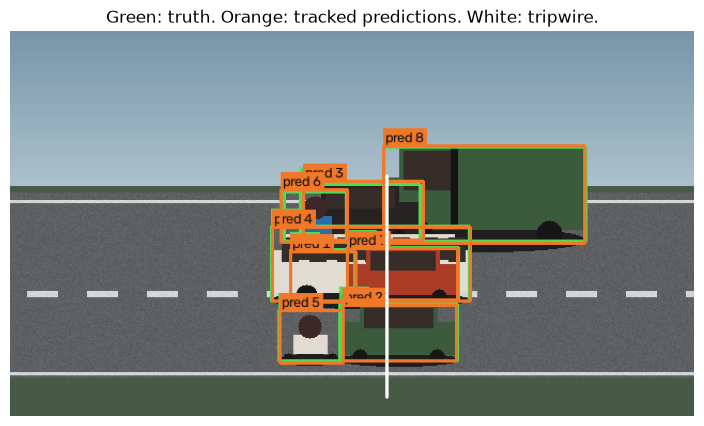

truth ids: [1, 2, 3, 4, 5, 6, 7, 8]
predicted ids: [1, 2, 3, 4, 5, 6, 7, 8]


In [9]:
index = 30
frame, objects = frames[index]
image = video.annotate_frame(frame, [obj["box"] for obj in objects], [f"gt {obj['track_id']}" for obj in objects])
image = video.annotate_frame(
    image,
    [track["box"] for track in tracks[index]],
    [f"pred {track['track_id']}" for track in tracks[index]],
    colour=(40, 120, 240),
)
cv2.line(image, tuple(int(v) for v in line["p1"]), tuple(int(v) for v in line["p2"]), (255, 255, 255), 2)
plt.figure(figsize=(10, 5))
plt.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
plt.axis("off")
plt.title("Green: truth. Orange: tracked predictions. White: tripwire.")
plt.show()
print("truth ids:", [obj["track_id"] for obj in objects])
print("predicted ids:", [track["track_id"] for track in tracks[index]])


## 7. Convert counts into a rate, with the caveat attached

Six seconds of video can support a rate in vehicles per second. It cannot support a
stable hourly forecast: traffic varies by time of day, and a six-second sample is
not a random sample of the day. `flow_summary` returns the extrapolated hourly figure
with `extrapolated: True` and an explicit note. Report the caveat, not just the
number.


In [10]:
duration = config.frames / config.fps
flow = counting.flow_summary(tracked["counts"], duration_s=duration, lanes=3)
print("clip seconds:", round(duration, 2))
for key, value in flow.items():
    print(" ", key, ":", value)

print("tracker processing seconds:", round(tracking_seconds, 3))
print("measured tracker RTF:", round(tracking_seconds / duration, 3))


clip seconds: 6.0
  total : 8
  duration_s : 6.0
  rate_per_s : 1.333
  per_hour : 4800.0
  per_lane_per_hour : 1600.0
  lanes : 3
  extrapolated : True
  note : per-hour figures extrapolate a few seconds of video; treat as a rate, not a forecast
tracker processing seconds: 0.012
measured tracker RTF: 0.002


## Explanation of the code

- `render_scene` returns `(frame, objects)` for every frame.

- Ground-truth objects include occluded vehicles; the drawing hides them, but the
  annotations do not.
- `createBackgroundSubtractorMOG2` updates a running background model. The mask is
  a pixel-level change map, not an object list.
- `tracking.track_detections` matches predicted boxes to detections, votes on class,
  and keeps a track alive through `max_age` missed frames.
- `tracker_report` matches predicted tracks to truth boxes by IoU and then checks
  identity; the same box with a new id counts as an ID switch.
- `run_counter` uses signed area to decide which side of the line a point is on and
  stores the previous side per track.
- `flow_summary` divides by the clip duration and labels the hourly figure as an
  extrapolation.

## Expected output

The scene has 60 frames and 8 vehicles. The oracle counter should match the expected
crossings exactly. The simulated detector drops detections and jitters boxes; the
tracker report will therefore show some false negatives and possibly an ID switch.
The tracked count may differ from the expected count; in the executed run here it
still matched exactly. Those numbers are the result of this run, not a promise about
a real camera.

## Interpretation of results

MOTA near 1 with zero ID switches means the tracker kept identity through the
simulated misses. A negative or low MOTA with a high fragment count means tracks are
breaking and re-forming; lowering `min_hits` or raising `max_age` may help, but both
changes also let false positives survive. Counting errors can come from three
different places: a missed detection, a fragmented identity, or a geometry bug. The
report separates them, so do not fix all three at once.

Do not report the hourly flow as a forecast. Report vehicles per second for the clip,
the clip duration, the lane count assumption, and the extrapolation caveat.

## Practical exercises

1. Set `shake=3` in the scene config. Does the background mask become useless? Does
   the tracker still work? Explain the difference.
2. Raise the detection drop rate from every eleventh frame to every third frame and
   compare MOTA and count error.
3. Change the counter anchor from `center` to `bottom` and compare event frames.
4. Compute the tracker's unique track count and compare it with the number of
   crossings. Explain why they are not the same metric.

## Challenge

Add a second counting line and compute directional flow. Then break one assumption
deliberately, such as a bus occluding a car for eight frames, and report which metric
moves first. Propose one change to the tracker and state its cost.

## Limitations

The scene, detector errors, and tracks are simulated. Oracle counts show what the
tracker could do with perfect detections; the injected false positives, misses,
and identity switches do not cover real occlusion, lighting, or camera motion.
The reported MOTA and flow rate therefore validate the analytics pipeline under
stated assumptions, not performance on road footage. Replace the simulator with
a licensed, annotated video and re-evaluate before making deployment claims.

## Common mistakes and troubleshooting

| Symptom | Likely cause | Fix |
| --- | --- | --- |
| Background mask is almost all white | Model not warmed up or camera moving | Feed more frames; check shake |
| Tracker creates a new id every frame | IoU threshold too high or boxes jitter too much | Lower threshold; smooth boxes |
| Every vehicle counted twice | Fragmented track with a new id | Raise `max_age`; inspect ID switches |
| Count is zero | Line outside the frame or wrong anchor | Print `p1`, `p2`, and one box |
| Negative MOTA | More errors than ground-truth objects | That is possible; inspect FN/FP/IDSW separately |
| Hourly flow looks huge | Extrapolating a short clip | Report per-second rate and the caveat |
| Video writer fails | Codec not available in the OpenCV build | This notebook uses in-memory frames; no codec needed |

## Summary

You rendered a scene with exact trajectories, inspected frames, ran a motion
baseline, tracked noisy detections, counted a tripwire, and measured tracking and
counting errors. The important result is the separation of detection, identity, and
geometry errors, plus a flow number with its limitations attached.

## Further reading

- Bewley et al., "Simple Online and Realtime Tracking", ICIP 2016.
- Wojke et al., "Simple Online and Realtime Tracking with a Deep Association Metric", ICIP 2017.
- Bernardin and Stiefelhagen, "Evaluating Multiple Object Tracking Performance: The CLEAR MOT Metrics", EURASIP 2008.
- The repository's `video_core.tracking`, `video_core.counting`, `video_core.metrics`, and `tests/test_video_ai.py`.
